# 3. From labelled points to classified objects


Run the whole raster workflow: segment an image, measure objects, transfer point
labels, inspect a spatial holdout, compare classifiers on that partition, and save a fitted model and map.
XGBoost is included when installed; the rest runs with the notebook extra alone.


This notebook runs independently and creates its own small, synthetic four-band
GeoTIFF. It needs no data downloads. Use the repository checkout and install
`python -m pip install -e ".[notebooks]"` from its root, then launch `jupyter lab`.
See the [notebook setup guide](https://obia.sefa.ai/examples/) for details.

Run the cells from top to bottom. Files go into this notebook's subdirectory of
`example_outputs/`; rerunning replaces those example files. All OBIA band selections
use **zero-based numeric indices** into the loaded raster.

[Download this notebook](03_classification.ipynb)

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from rasterio.transform import from_origin

from obia.handlers.geotif import open_geotiff
from importlib.util import find_spec

import joblib
from matplotlib.colors import ListedColormap
from sklearn.impute import SimpleImputer
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

from obia.classification import classify, split_objects
from obia.features import extract_features
from obia.segmentation import create_segments
from obia.utils.utils import label_segments

%matplotlib inline
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 11})
output_dir = Path("example_outputs") / "03_classification"
output_dir.mkdir(parents=True, exist_ok=True)

## Make and load a tiny raster

The scene contains three invented surface types, with different values in bands
0–3 and different amounts of variation. The grid is 96 × 128 pixels at 2 m per
pixel in a projected CRS. These coordinates are only for demonstrating geospatial
operations; the scene is not an observation of a real location.

Replace this cell with `image = open_geotiff("your_image.tif")` for your own data.
The loader reads all file bands here. Its optional `bands=` argument follows
Rasterio's **one-based** file numbering; subsequent OBIA selections are zero-based.

In [2]:
rng = np.random.default_rng(42)
rows, cols = np.indices((96, 128))
reference = np.zeros(rows.shape, dtype=np.uint8)
reference[rows < 46] = 1
reference[((rows - 58) / 25) ** 2 + ((cols - 83) / 31) ** 2 < 1] = 2

# Each row contains values for bands [0, 1, 2, 3] of one surface type.
spectra = np.array([[0.48, 0.36, 0.22, 0.32],
                    [0.12, 0.38, 0.15, 0.68],
                    [0.08, 0.18, 0.30, 0.04]])
noise = np.array([0.015, 0.045, 0.006])[reference, None]
values = np.clip(spectra[reference] + rng.normal(size=(96, 128, 4)) * noise, 0, 1)
transform = from_origin(500_000, 2_200_000, 2, 2)
raster_path = output_dir / "sample.tif"
with rasterio.open(raster_path, "w", driver="GTiff", height=96, width=128,
                   count=4, dtype="float32", crs="EPSG:32604", transform=transform) as dst:
    dst.write(values.astype("float32").transpose(2, 0, 1))

image = open_geotiff(raster_path)
image.rasterio_obj.close()  # The loaded values, masks, CRS, and transform remain available.
print(f"Loaded array: {image.img_data.shape}; CRS: {image.crs}")

Loaded array: (96, 128, 4); CRS: EPSG:32604


## Segment and measure

Choose a small, explicit feature set. Segment IDs, coordinates, reference class
codes, and previous predictions are not included as predictors.

In [3]:
polygons = create_segments(
    image, segmentation_bands=[0, 1, 2, 3], method="slic",
    n_segments=200, compactness=0.2, sigma=0.6, convert2lab=False,
)
objects = extract_features(
    polygons, image, bands=[0, 1, 2, 3], spectral=("mean", "std"), percentiles=(),
    indices={"normalized_difference": (3, 0)}, shape=("area", "circularity"),
)
feature_columns = [
    "b0_mean", "b1_mean", "b2_mean", "b3_mean", "b0_std", "b3_std",
    "index_normalized_difference_b3_b0_mean", "shape_area", "shape_circularity",
]
print(f"{len(objects)} objects; {len(feature_columns)} selected features")

178 objects; 9 selected features


## Transfer point labels to objects

For this demonstration, sample labelled points from the known synthetic scene.
For a real project, load independently interpreted or surveyed points with
`gpd.read_file("labels.gpkg").to_crs(objects.crs)`. Their label column must be
named `class`.

`label_segments()` returns objects with an unambiguous `feature_class` and IDs of
objects containing conflicting labels. Conflicting and unlabelled objects are
excluded from training, but remain in the prediction map. Inspect conflicts to
decide whether to revise segmentation or labels.

Labelled objects: 140; conflicting objects excluded: 2


,labelled_objects
feature_class,
forest,63
soil,53
water,24


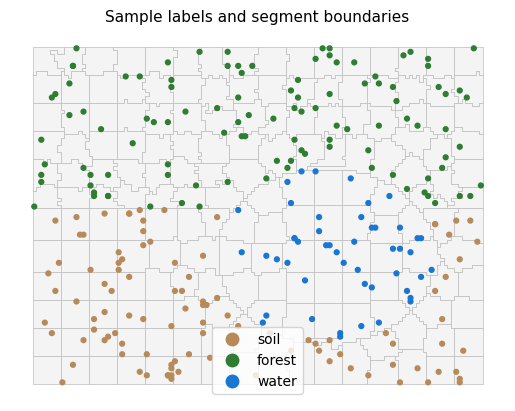

In [4]:
class_names = np.array(["soil", "forest", "water"])
class_cmap = ListedColormap(["#b88a59", "#2e7d32", "#1976d2"])
point_rng = np.random.default_rng(7)
point_rows = point_rng.integers(0, 96, size=260)
point_cols = point_rng.integers(0, 128, size=260)
xs, ys = rasterio.transform.xy(image.transform, point_rows, point_cols)
labelled_points = gpd.GeoDataFrame(
    {"class": class_names[reference[point_rows, point_cols]]},
    geometry=gpd.points_from_xy(xs, ys), crs=image.crs,
)
training, mixed_ids = label_segments(objects, labelled_points)
print(f"Labelled objects: {len(training)}; conflicting objects excluded: {len(mixed_ids)}")
display(training.feature_class.value_counts().rename("labelled_objects").to_frame())

fig, ax = plt.subplots(figsize=(6, 4), layout="constrained")
objects.plot(ax=ax, color="#f4f4f4", edgecolor="#bdbdbd", linewidth=0.5)
labelled_points.plot(ax=ax, column="class", categorical=True, categories=list(class_names),
                     cmap=class_cmap, markersize=12, legend=True)
ax.set_title("Sample labels and segment boundaries")
ax.set_axis_off()
plt.show()

## Inspect a spatial holdout before fitting

Hold out whole square blocks and keep training geometries away from test
geometries. This toy example uses 64 m blocks and a 2 m buffer in its projected
CRS. Choose distances that match spatial dependence and the intended prediction
area for real imagery; these small distances are only for this synthetic scene.

`test_size=0.25` holds out a quarter of occupied blocks, not a quarter of objects.
If one training object meets the buffer, its entire block is excluded. Inspect
both the map and class counts: every class must remain in training and testing.
Unlabelled objects are shown in gray and have no split assignment.

Check the water row below: buffering leaves very few training examples. In a
real project, collect more independent labelled groups if a class is this
poorly represented. Requiring each class to be present is only a basic check
and does not establish that the training sample is adequate.

When real site or field IDs are available, use `method="grouped", groups="site_id"`
instead of grid blocks. Grouping follows the underlying sampling unit. The
[validation guide](https://obia.sefa.ai/usage/validation/) discusses these choices
with references to Roberts et al. (2017) and Wadoux et al. (2021).

subset,train,test,excluded
feature_class,,,
forest,32,18,13
soil,37,12,4
water,2,8,14


{'n_train': 71, 'n_test': 38, 'n_excluded': 31}


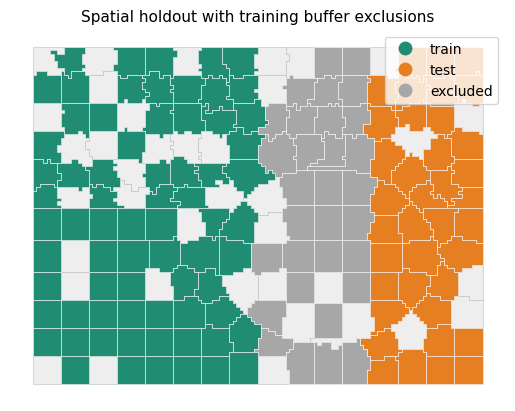

In [5]:
partition = split_objects(
    training, method="spatial", block_size=64, block_origin=(500_000, 2_200_000),
    buffer_distance=2, test_size=0.25, random_state=42,
)
display(partition.class_counts)
print({key: partition.metadata[key] for key in ("n_train", "n_test", "n_excluded")})

fig, ax = plt.subplots(figsize=(6, 4), layout="constrained")
objects.plot(ax=ax, color="#eeeeee", edgecolor="#bbbbbb", linewidth=0.4)
partition.assignments.plot(
    ax=ax, column="subset", categorical=True, categories=["train", "test", "excluded"],
    cmap=ListedColormap(["#218c74", "#e67e22", "#a7a7a7"]), legend=True,
    edgecolor="white", linewidth=0.4,
)
ax.set_title("Spatial holdout with training buffer exclusions")
ax.set_axis_off()
plt.show()
partition.assignments.to_file(output_dir / "validation_split.gpkg", driver="GPKG")

## Compare a few classifiers

Reuse the same spatial partition and feature columns for every model. OBIA fits
automatic scaling on the training subset for logistic regression; tree models
do not need that scaler. Buffered objects are excluded from fitting and scoring.
The split seed is separate from model seeds.

These easy synthetic classes demonstrate the API, not real-world accuracy.
Comparing or tuning models repeatedly on this holdout makes it a validation set;
reserve another untouched final test set for a real model-selection workflow.
The [validation guide](https://obia.sefa.ai/usage/validation/) demonstrates
nested grouped cross-validation and explains map accuracy sampling.

To include XGBoost, install `python -m pip install -e ".[notebooks,xgboost]"`
from the repository root and restart the kernel.

In [6]:
methods = {
    "Random forest": ("rf", {"n_estimators": 60, "random_state": 42, "n_jobs": 1}),
    "Logistic regression": ("logistic_regression", {"max_iter": 500}),
    "Histogram boosting": ("hist_gradient_boosting", {
        "max_iter": 60, "min_samples_leaf": 5, "random_state": 42,
    }),
}
if find_spec("xgboost") is not None:
    methods["XGBoost"] = ("xgboost", {
        "n_estimators": 40, "max_depth": 3, "random_state": 42, "n_jobs": 1,
    })
else:
    print("XGBoost is not installed; comparing the three scikit-learn models.")

results, scores = {}, []
for name, (method, parameters) in methods.items():
    result = classify(
        objects, training, method=method, feature_columns=feature_columns,
        split=partition, compute_reports=True, **parameters,
    )
    results[name] = result
    cm = result.confusion_matrix
    scores.append({"model": name, "holdout_objects": int(cm.sum()),
                   "holdout_accuracy": np.trace(cm) / cm.sum()})
pd.DataFrame(scores).set_index("model")

,holdout_objects,holdout_accuracy
model,,
Random forest,38,1.000000
Logistic regression,38,0.973684
Histogram boosting,38,1.000000
XGBoost,38,1.000000


              precision    recall  f1-score   support

      forest       1.00      1.00      1.00        18
        soil       1.00      1.00      1.00        12
       water       1.00      1.00      1.00         8

    accuracy                           1.00        38
   macro avg       1.00      1.00      1.00        38
weighted avg       1.00      1.00      1.00        38



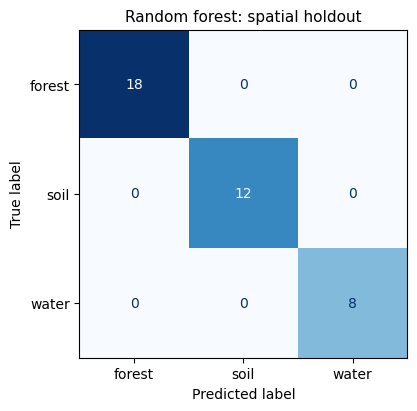

In [7]:
evaluated = results["Random forest"]
print(evaluated.report)
fig, ax = plt.subplots(figsize=(4.5, 4), layout="constrained")
ConfusionMatrixDisplay(evaluated.confusion_matrix, display_labels=evaluated.classes).plot(
    ax=ax, colorbar=False, cmap="Blues",
)
ax.set_title("Random forest: spatial holdout")
plt.show()

## Supply your own scikit-learn pipeline

A custom pipeline owns its preprocessing. This one can impute missing numeric
values, scale features, and fit a linear SVM. OBIA clones and fits it on the
training partition. `LinearSVC` does not provide class probabilities, so its
`prediction_margin` is missing; ordinary class predictions still work.

In [8]:
pipeline = make_pipeline(
    SimpleImputer(strategy="median"), StandardScaler(), LinearSVC(random_state=42),
)
svm_result = classify(
    objects, training, method=pipeline, feature_columns=feature_columns,
    split=partition,
)
assert svm_result.probabilities is None
svm_result.classified[["segment_id", "predicted_class", "prediction_margin"]].head()

,segment_id,predicted_class,prediction_margin
0,1,forest,NaN
1,12,forest,NaN
2,16,forest,NaN
3,6,forest,NaN
4,3,forest,NaN


## Fit all labels and map the result

After evaluation, fit a fresh random forest on all labelled objects with
`test_size=None`. OBIA does not do this refit automatically. The earlier report
belongs to the holdout model, not this final fit. This refit includes objects
previously assigned to the holdout or excluded by its buffer.

For probabilistic models, `prediction_margin` is the gap between the two largest
class probabilities. Small gaps highlight ambiguous predictions; a large gap is
not a guarantee of correctness or a calibrated accuracy estimate.

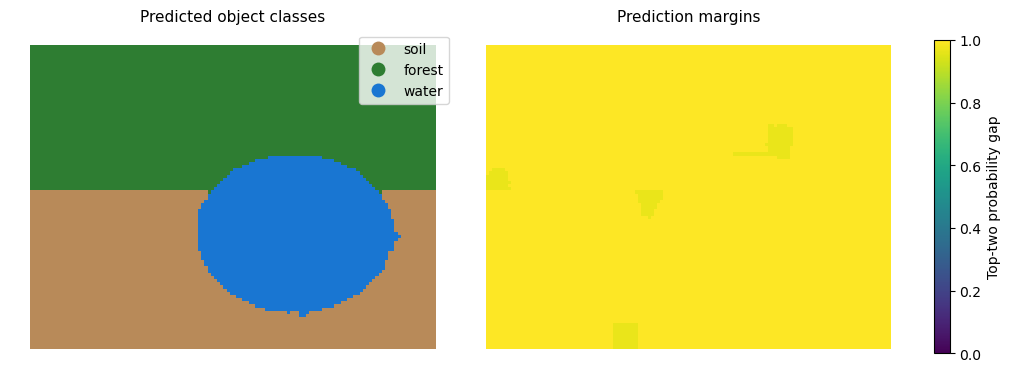

In [9]:
final = classify(
    objects, training, method="rf", feature_columns=feature_columns, test_size=None,
    n_estimators=60, random_state=42, n_jobs=1,
)
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
final.classified.plot(
    column="predicted_class", ax=axes[0], categorical=True, categories=list(class_names),
    cmap=class_cmap, legend=True,
)
axes[0].set_title("Predicted object classes")
final.classified.plot(
    column="prediction_margin", ax=axes[1], cmap="viridis", vmin=0, vmax=1,
    legend=True, legend_kwds={"label": "Top-two probability gap", "shrink": 0.8},
)
axes[1].set_title("Prediction margins")
for ax in axes:
    ax.set_axis_off()
plt.show()

## Save the map and reuse the fitted model

Save feature order with the model. To predict a different scene, extract the
same features with the same band ordering and settings, then select columns in
that order. Here we reload our own model and predict the existing objects as a
simple round-trip check.

In [10]:
final.classified.to_file(output_dir / "classified_objects.gpkg", layer="objects", driver="GPKG")
joblib.dump({"model": final.model, "feature_columns": final.feature_columns},
            output_dir / "classifier.joblib")
saved = joblib.load(output_dir / "classifier.joblib")
predictions = saved["model"].predict(objects.loc[:, list(saved["feature_columns"])])
np.testing.assert_array_equal(predictions, final.classified.predicted_class)
saved_objects = gpd.read_file(output_dir / "classified_objects.gpkg", layer="objects")
assert len(saved_objects) == len(objects)
print(f"Saved classified polygons and a reusable classifier to {output_dir}")

Saved classified polygons and a reusable classifier to example_outputs/03_classification


Try `extra_trees`, `knn`, or a different scikit-learn pipeline in the comparison.
Use each estimator's own parameters and check its input requirements. The
[classification guide](https://obia.sefa.ai/usage/classification/) covers all named choices,
probabilities, spatial class constraints, and SHAP explanations.